# Attack Surface Analysis for Autonomous Vehicles

**Module 05 · Cybersecurity (ISO/SAE 21434)** · Notebook 3 of 4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/05_Cybersecurity_ISO21434/03_attack_surface_analysis.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [TARA](02_tara.ipynb) | ISO/SAE 21434:2021 (cl. 15.6, Annex G), CVSS v3.1, ISO 14229-1:2020, IEEE 1609.2 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

**Identifying and mitigating cybersecurity risks per ISO/SAE 21434**

## Learning objectives

1. Enumerate the attack surfaces of an automated vehicle and classify them by attack vector (Network, Adjacent, Local, Physical).
2. Build an attack tree with AND/OR aggregation and find the most feasible attack path (ISO/SAE 21434 cl. 15.6 → 15.7).
3. Apply defence in depth and map security controls to attack surfaces, distinguishing link integrity from physical-world sensor attacks.
4. Compute real CVSS v3.1 base scores and map the exploitability sub-score to attack feasibility (Annex G.3).
5. Understand the principle and limits of a timing-based CAN intrusion detector.

## 1. Attack surface overview

### Automated-vehicle communication interfaces

```
                        +-----------------+
                        |   Cloud / OEM   |
                        |     backend     |
                        +--------+--------+
                                 | cellular (Network)
   +-----------------------------+------------------------------+
   | VEHICLE                     |                              |
   |  +-------------+      +-----+-----+      +-------------+   |
   |  | Telematics  +------+  Gateway  +------+  ADAS / AD  |   |
   |  +-------------+      +-----+-----+      |    ECU      |   |
   |                             | CAN-FD /   +------+------+   |
   |  +-------------+      +-----+-----+ Ethernet     |          |
   |  | Infotainment+------+  Body ECU |      +------+------+   |
   |  +------+------+      +-----------+      |  Sensors    |   |
   |         |              OBD-II (Local)    | cam/LiDAR/  |   |
   +---------+--------------------------------+ radar/GNSS  +---+
             | Bluetooth / Wi-Fi / USB          +------+------+
     +-------+-------+     +-------------+             | optical / RF
     | Mobile device |     |  V2X (RSU,  |       physical environment
     +---------------+     |  vehicles)  |
                           +-------------+
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from dataclasses import dataclass, field
from typing import List, Dict, Optional
from enum import Enum
from IPython.display import display

OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
rng = np.random.default_rng(42)
print('Attack surface analysis tools loaded.')

Attack surface analysis tools loaded.


## 2. Attack surface enumeration

The attack vector classes follow CVSS and ISO/SAE 21434 Annex G.4:

| Class | Meaning | Automotive examples |
|---|---|---|
| **Network** | Reachable remotely, beyond the local radio range | Cellular telematics, backend/OTA |
| **Adjacent** | Requires logical or radio proximity | Bluetooth, Wi-Fi, V2X, GNSS (RF in range) |
| **Local** | Requires local access to the component, e.g. a connected tester or removable media | OBD-II diagnostic tester, USB, SD card |
| **Physical** | Requires physically touching or manipulating the component | Splicing into bus wiring, JTAG/debug port, removing an ECU |

Sensors add a channel that fits none of these classes well: the **physical environment** (patches, light, laser, RF reflections).
No access to the vehicle is needed. We tag it separately and map it to *Physical* when a 21434 class is required. As Notebooks 1 and 2 showed, the attack-vector feasibility method then underrates these attacks.

Classifying OBD-II as *Local* rather than *Physical* is a documented choice in this module. Practitioners differ, so record the convention in your TARA method.

In [2]:
class AttackVector(Enum):
    NETWORK = 'Network (remote, e.g. cellular)'
    ADJACENT = 'Adjacent (radio/logical proximity, e.g. Bluetooth, Wi-Fi, V2X, GNSS)'
    LOCAL = 'Local (e.g. OBD-II diagnostic tester, USB/SD media)'
    PHYSICAL = 'Physical (touch/manipulate component, e.g. bus wiring, debug port)'
    PHYSICAL_ENVIRONMENT = 'Physical environment (sensor input; no vehicle access needed)'

    @property
    def iso21434_class(self):
        """Class used for Annex G.4 feasibility and the Annex E CAL table."""
        return 'Physical' if self is AttackVector.PHYSICAL_ENVIRONMENT else self.name.capitalize()

FEASIBILITY_FROM_VECTOR = {'Network': 'High', 'Adjacent': 'Medium', 'Local': 'Low', 'Physical': 'Very Low'}

@dataclass
class AttackSurface:
    """Represents an attack surface in the vehicle system."""
    id: str
    name: str
    attack_vector: AttackVector
    connected_assets: List[str]
    protocols: List[str]
    authentication: str
    confidentiality: str
    known_vulnerabilities: List[str] = field(default_factory=list)
    mitigations: List[str] = field(default_factory=list)

attack_surfaces = [
    AttackSurface('AS-001', 'OBD-II diagnostic port', AttackVector.LOCAL,
                  ['Gateway', 'All diagnosable ECUs'], ['CAN', 'UDS (ISO 14229)', 'DoIP (ISO 13400)'],
                  'UDS Authentication 0x29 (ISO 14229-1:2020, certificate-based); legacy SecurityAccess 0x27 seed/key',
                  'None (typically)',
                  ['Direct bus access if not filtered', 'Diagnostic service abuse', 'Weak or leaked seed/key algorithms'],
                  ['Gateway filtering of diagnostic traffic', 'UDS Authentication 0x29 with role-based access',
                   'Lockout after failed authentication', 'Diagnostic session logging']),
    AttackSurface('AS-002', 'Telematics control unit (TCU)', AttackVector.NETWORK,
                  ['Gateway', 'Backend server', 'Infotainment'], ['LTE/5G', 'TCP/IP', 'TLS'],
                  'PKI, mutual TLS', 'TLS 1.3',
                  ['Cellular protocol attacks', 'Rogue base station', 'Backend API vulnerabilities'],
                  ['Mutual TLS authentication', 'Certificate pinning', 'Secure boot', 'Intrusion detection']),
    AttackSurface('AS-003', 'Infotainment system', AttackVector.ADJACENT,
                  ['Gateway', 'Smartphone', 'USB storage'], ['Bluetooth', 'Wi-Fi', 'USB', 'CarPlay/Android Auto'],
                  'Bluetooth pairing', 'Bluetooth link encryption',
                  ['Bluetooth stack vulnerabilities (e.g. BlueBorne)', 'Malicious USB media', 'Wi-Fi attacks', 'Media file parser exploits'],
                  ['Network segmentation', 'Input validation', 'Sandboxing', 'Regular updates']),
    AttackSurface('AS-004', 'V2X communication', AttackVector.ADJACENT,
                  ['ADAS/AD ECU', 'Other vehicles', 'Roadside units'], ['ITS-G5 / IEEE 802.11p (DSRC)', 'LTE-V2X / NR-V2X (PC5)'],
                  'Digital signatures with IEEE 1609.2 / ETSI TS 103 097 certificates (SCMS in the US, C-ITS CCMS in the EU)',
                  'None for broadcast safety messages (signed, not encrypted)',
                  ['Insider with valid certificate sends false data', 'Sybil attacks', 'Replay', 'Radio jamming (DoS)'],
                  ['Signature verification', 'Plausibility checks / misbehaviour detection',
                   'Certificate revocation', 'Rate limiting']),
    AttackSurface('AS-005', 'Perception sensors (camera, LiDAR, radar)', AttackVector.PHYSICAL_ENVIRONMENT,
                  ['Perception ECU', 'Sensor fusion'], ['Optical/RF sensing channel', 'Sensor link: MIPI CSI-2/GMSL, Automotive Ethernet'],
                  'None on the physical sensing channel; the sensor-to-ECU link can be integrity-protected',
                  'None (internal)',
                  ['Adversarial patches', 'LiDAR spoofing/jamming', 'Radar interference', 'Camera dazzling'],
                  ['Sensor fusion cross-validation', 'Plausibility monitoring', 'OOD detection',
                   'Link integrity protection (addresses link tampering only)']),
    AttackSurface('AS-006', 'GNSS receiver', AttackVector.ADJACENT,
                  ['Localisation', 'Map matching', 'V2X position'], ['GPS L1/L5', 'Galileo E1/E5'],
                  'Galileo OSNMA navigation message authentication (where supported)', 'None (open signals)',
                  ['GNSS spoofing', 'GNSS jamming', 'Meaconing (replay)'],
                  ['Multi-constellation consistency checks', 'IMU/odometry cross-check', 'Map-matching plausibility',
                   'Navigation message authentication (OSNMA)']),
    AttackSurface('AS-007', 'In-vehicle network (CAN/CAN-FD/Ethernet)', AttackVector.PHYSICAL,
                  ['All ECUs on the segment'], ['CAN', 'CAN-FD', 'Automotive Ethernet'],
                  'SecOC (AUTOSAR), if deployed', 'MACsec (Ethernet), if deployed',
                  ['Bus injection', 'Message replay', 'DoS via bus flooding', 'ECU impersonation'],
                  ['SecOC authentication', 'Intrusion detection', 'Network segmentation', 'Freshness counters']),
    AttackSurface('AS-008', 'OTA update interface', AttackVector.NETWORK,
                  ['All updateable ECUs', 'Backend'], ['TLS', 'OEM OTA protocol (e.g. Uptane-style metadata)'],
                  'PKI and code signing (end-to-end)', 'TLS 1.3 in transit; optional package encryption',
                  ['Rollback attacks', 'Compromised update server', 'Man-in-the-middle', 'Interrupted update'],
                  ['Secure boot chain', 'Code signing verification', 'Rollback protection', 'A/B partition scheme']),
]
print(f'Defined {len(attack_surfaces)} attack surfaces')

Defined 8 attack surfaces


In [3]:
summary = pd.DataFrame([{
    'ID': s.id, 'Name': s.name, 'Vector': s.attack_vector.name.replace('_', ' ').title(),
    '21434 class': s.attack_vector.iso21434_class,
    'G.4 feasibility': FEASIBILITY_FROM_VECTOR[s.attack_vector.iso21434_class],
    'Authentication': s.authentication, 'Vulns': len(s.known_vulnerabilities)} for s in attack_surfaces])
pd.set_option('display.max_colwidth', 70)
display(summary)
print('--- Attack surfaces (text summary) ---')
for r in summary.to_dict('records'):
    print(f"  {r['ID']} {r['Name']}: {r['Vector']} -> 21434 class {r['21434 class']} (G.4 feasibility {r['G.4 feasibility']})")

,ID,Name,Vector,21434 class,G.4 feasibility,Authentication,Vulns
0,AS-001,OBD-II diagnostic port,Local,Local,Low,"UDS Authentication 0x29 (ISO 14229-1:2020, certificate-based); leg...",3
1,AS-002,Telematics control unit (TCU),Network,Network,High,"PKI, mutual TLS",3
2,AS-003,Infotainment system,Adjacent,Adjacent,Medium,Bluetooth pairing,4
3,AS-004,V2X communication,Adjacent,Adjacent,Medium,Digital signatures with IEEE 1609.2 / ETSI TS 103 097 certificates...,4
4,AS-005,"Perception sensors (camera, LiDAR, radar)",Physical Environment,Physical,Very Low,None on the physical sensing channel; the sensor-to-ECU link can b...,4
5,AS-006,GNSS receiver,Adjacent,Adjacent,Medium,Galileo OSNMA navigation message authentication (where supported),3
6,AS-007,In-vehicle network (CAN/CAN-FD/Ethernet),Physical,Physical,Very Low,"SecOC (AUTOSAR), if deployed",4
7,AS-008,OTA update interface,Network,Network,High,PKI and code signing (end-to-end),4


--- Attack surfaces (text summary) ---
  AS-001 OBD-II diagnostic port: Local -> 21434 class Local (G.4 feasibility Low)
  AS-002 Telematics control unit (TCU): Network -> 21434 class Network (G.4 feasibility High)
  AS-003 Infotainment system: Adjacent -> 21434 class Adjacent (G.4 feasibility Medium)
  AS-004 V2X communication: Adjacent -> 21434 class Adjacent (G.4 feasibility Medium)
  AS-005 Perception sensors (camera, LiDAR, radar): Physical Environment -> 21434 class Physical (G.4 feasibility Very Low)
  AS-006 GNSS receiver: Adjacent -> 21434 class Adjacent (G.4 feasibility Medium)
  AS-007 In-vehicle network (CAN/CAN-FD/Ethernet): Physical -> 21434 class Physical (G.4 feasibility Very Low)
  AS-008 OTA update interface: Network -> 21434 class Network (G.4 feasibility High)


### V2X security in brief

- V2X safety messages (CAM/BSM, DENM, CPM) are **broadcast and signed, not encrypted**. Signatures give authenticity and integrity, but not confidentiality. Privacy comes from **pseudonym certificates** that change over time.
- The security header and certificate formats are **IEEE 1609.2** (US) and **ETSI TS 103 097** (EU), which is based on it. The PKIs differ: the **SCMS** in the US, and the EU **C-ITS Credential Management System (CCMS)** with its trust-list model (ETSI TS 102 940/941).
- A valid signature proves that the sender holds a certificate. It does **not** prove that the content is true. An insider device, or one with an extracted key, can sign false data. Receivers therefore still need plausibility checks and misbehaviour detection, and misbehaving certificates must be revoked.

More on cooperative driving: [V2X cooperative driving](../07_Runtime_Assurance_and_Operations/02_v2x_cooperative_driving.ipynb).

## 3. Attack tree analysis

Attack trees (Schneier, 1999) are a standard way to document **attack path analysis** (ISO/SAE 21434 cl. 15.6).
The leaves carry attack-potential factors (Annex G.2). The aggregation follows the convention of [Notebook 2](02_tara.ipynb):
- **OR** node: the attacker takes the easiest child, so we use the child with the minimum attack potential.
- **AND** node: all children are needed. Per factor, we take the maximum over the children.

The root's value is the **most feasible attack path**, which feeds the feasibility rating (cl. 15.7).

> **Illustrative data:** factor values are expert-judgement examples for teaching.

In [4]:
FACTORS = ['elapsed_time', 'expertise', 'knowledge', 'window', 'equipment']
FACTOR_VALUES = {
    'elapsed_time': {0, 1, 4, 17, 19}, 'expertise': {0, 3, 6, 8},
    'knowledge': {0, 3, 7, 11}, 'window': {0, 1, 4, 10}, 'equipment': {0, 4, 7, 9},
}

def feasibility_from_potential(ap):
    return 'High' if ap <= 13 else 'Medium' if ap <= 19 else 'Low' if ap <= 24 else 'Very Low'

@dataclass
class AttackNode:
    """Node in an attack tree. Leaves carry Annex G.2 factor values (elapsed, expertise, knowledge, window, equipment)."""
    id: str
    description: str
    node_type: str                      # 'AND', 'OR' or 'LEAF'
    factors: Optional[tuple] = None     # only for leaves
    children: List['AttackNode'] = field(default_factory=list)

    def __post_init__(self):
        if self.node_type == 'LEAF':
            assert self.factors is not None and len(self.factors) == 5
            for f, v in zip(FACTORS, self.factors):
                assert v in FACTOR_VALUES[f], f'{self.id}: invalid {f} value {v}'

    def add_child(self, child):
        self.children.append(child)
        return child

def evaluate(node):
    """Return (factor dict, list of leaf ids on the most feasible path)."""
    if node.node_type == 'LEAF':
        return dict(zip(FACTORS, node.factors)), [node.id]
    results = [evaluate(c) for c in node.children]
    if node.node_type == 'OR':
        return min(results, key=lambda r: sum(r[0].values()))
    if node.node_type == 'AND':
        agg = {f: max(r[0][f] for r in results) for f in FACTORS}
        return agg, [leaf for r in results for leaf in r[1]]
    raise ValueError(node.node_type)

def build_perception_attack_tree():
    root = AttackNode('G0', 'Suppress or spoof pedestrian detections used by AEB', 'OR')
    g1 = root.add_child(AttackNode('G1', 'Attack the sensing channel (physical environment)', 'OR'))
    g1.add_child(AttackNode('A1.1', 'Deploy adversarial patch in the scene', 'LEAF', (4, 6, 3, 1, 0)))
    g1.add_child(AttackNode('A1.2', 'Spoof LiDAR returns with a synchronised laser', 'LEAF', (4, 6, 3, 4, 7)))
    g1.add_child(AttackNode('A1.3', 'Dazzle the camera with a light source', 'LEAF', (0, 3, 0, 4, 0)))
    g2 = root.add_child(AttackNode('G2', 'Inject forged object-list frames', 'AND'))
    g21 = g2.add_child(AttackNode('G2.1', 'Gain access to the in-vehicle network', 'OR'))
    g21.add_child(AttackNode('A2.1.1', 'Exploit telematics unit remotely', 'LEAF', (17, 6, 7, 0, 4)))
    g21.add_child(AttackNode('A2.1.2', 'Compromise infotainment via Bluetooth', 'LEAF', (4, 6, 3, 1, 4)))
    g21.add_child(AttackNode('A2.1.3', 'Splice into bus wiring at a bumper sensor', 'LEAF', (1, 3, 3, 4, 4)))
    g2.add_child(AttackNode('A2.2', 'Bypass gateway filtering to the AEB segment', 'LEAF', (4, 6, 7, 0, 0)))
    g2.add_child(AttackNode('A2.3', 'Forge frames (no message authentication)', 'LEAF', (1, 3, 3, 0, 0)))
    g3 = root.add_child(AttackNode('G3', 'Attack ML model integrity', 'OR'))
    g3.add_child(AttackNode('A3.1', 'Poison training data via the data supply chain', 'LEAF', (19, 8, 11, 1, 7)))
    g3.add_child(AttackNode('A3.2', 'Install a malicious model via OTA', 'LEAF', (17, 8, 11, 1, 7)))
    return root

def print_attack_tree(node, indent=0):
    agg, _ = evaluate(node)
    ap = sum(agg.values())
    tag = f'[{node.node_type}]' if node.node_type != 'LEAF' else '[leaf]'
    print(f"{'    ' * indent}{node.id} {tag} {node.description}: AP {ap} -> {feasibility_from_potential(ap)}")
    for c in node.children:
        print_attack_tree(c, indent + 1)

attack_tree = build_perception_attack_tree()
print('Attack tree: perception compromise (AP = attack potential, Annex G.2)')
print('=' * 80)
print_attack_tree(attack_tree)

agg, path = evaluate(attack_tree)
ap = sum(agg.values())
print(f"\nMost feasible attack path: {' AND '.join(path)} -> attack potential {ap} -> {feasibility_from_potential(ap)} feasibility")
for g in attack_tree.children:
    a, p = evaluate(g)
    print(f"  Best path within {g.id}: {' AND '.join(p)} (AP {sum(a.values())})")

Attack tree: perception compromise (AP = attack potential, Annex G.2)
G0 [OR] Suppress or spoof pedestrian detections used by AEB: AP 7 -> High
    G1 [OR] Attack the sensing channel (physical environment): AP 7 -> High
        A1.1 [leaf] Deploy adversarial patch in the scene: AP 14 -> Medium
        A1.2 [leaf] Spoof LiDAR returns with a synchronised laser: AP 24 -> Low
        A1.3 [leaf] Dazzle the camera with a light source: AP 7 -> High
    G2 [AND] Inject forged object-list frames: AP 25 -> Very Low
        G2.1 [OR] Gain access to the in-vehicle network: AP 15 -> Medium
            A2.1.1 [leaf] Exploit telematics unit remotely: AP 34 -> Very Low
            A2.1.2 [leaf] Compromise infotainment via Bluetooth: AP 18 -> Medium
            A2.1.3 [leaf] Splice into bus wiring at a bumper sensor: AP 15 -> Medium
        A2.2 [leaf] Bypass gateway filtering to the AEB segment: AP 17 -> Medium
        A2.3 [leaf] Forge frames (no message authentication): AP 7 -> High
    G3 [OR] Att

The most feasible path is a physical-environment attack, not a network attack. For perception, the cheapest attacks often need no access to the vehicle at all.
Branch G2 shows the AND effect: the cheapest network-access leaf (A2.1.3) is easy, but the path still needs the gateway bypass (A2.2), and that step dominates expertise and knowledge.

## 4. Defence-in-depth strategy

In [5]:
defense_layers = {
    'Layer 1: Perimeter security': {
        'description': 'First line of defence at system boundaries',
        'controls': ['Firewall between vehicle domains', 'TLS for external communications',
                     'Certificate-based authentication', 'Input validation at all interfaces']},
    'Layer 2: Network security': {
        'description': 'In-vehicle network protection',
        'controls': ['Network segmentation (safety vs non-safety domains)', 'SecOC for CAN message authentication',
                     'Intrusion detection system (IDS)', 'Rate limiting and anomaly detection']},
    'Layer 3: Host security': {
        'description': 'ECU-level protection',
        'controls': ['Secure boot with hardware root of trust', 'Code signing verification',
                     'Memory protection (MPU/MMU)', 'Secure key storage (HSM)']},
    'Layer 4: Application security': {
        'description': 'Software-level protection',
        'controls': ['Secure coding practices', 'Input validation and sanitisation',
                     'Privilege separation', 'Runtime integrity monitoring']},
    'Layer 5: Data security': {
        'description': 'Protection of sensitive data',
        'controls': ['Encryption at rest (e.g. AES-256)', 'Encryption in transit (TLS 1.3)',
                     'Secure key management', 'Data integrity verification']},
    'Layer 6: Monitoring & response': {
        'description': 'Detection and incident response across all layers',
        'controls': ['Security event logging', 'Vehicle security operations centre (VSOC)',
                     'Incident response procedures (cl. 13)', 'Secure OTA for rapid patching']},
}
print('Defence-in-depth strategy')
print('=' * 60)
for layer, details in defense_layers.items():
    print(f'\n{layer}')
    print(f"  {details['description']}")
    for control in details['controls']:
        print(f'  - {control}')

Defence-in-depth strategy

Layer 1: Perimeter security
  First line of defence at system boundaries
  - Firewall between vehicle domains
  - TLS for external communications
  - Certificate-based authentication
  - Input validation at all interfaces

Layer 2: Network security
  In-vehicle network protection
  - Network segmentation (safety vs non-safety domains)
  - SecOC for CAN message authentication
  - Intrusion detection system (IDS)
  - Rate limiting and anomaly detection

Layer 3: Host security
  ECU-level protection
  - Secure boot with hardware root of trust
  - Code signing verification
  - Memory protection (MPU/MMU)
  - Secure key storage (HSM)

Layer 4: Application security
  Software-level protection
  - Secure coding practices
  - Input validation and sanitisation
  - Privilege separation
  - Runtime integrity monitoring

Layer 5: Data security
  Protection of sensitive data
  - Encryption at rest (e.g. AES-256)
  - Encryption in transit (TLS 1.3)
  - Secure key managemen

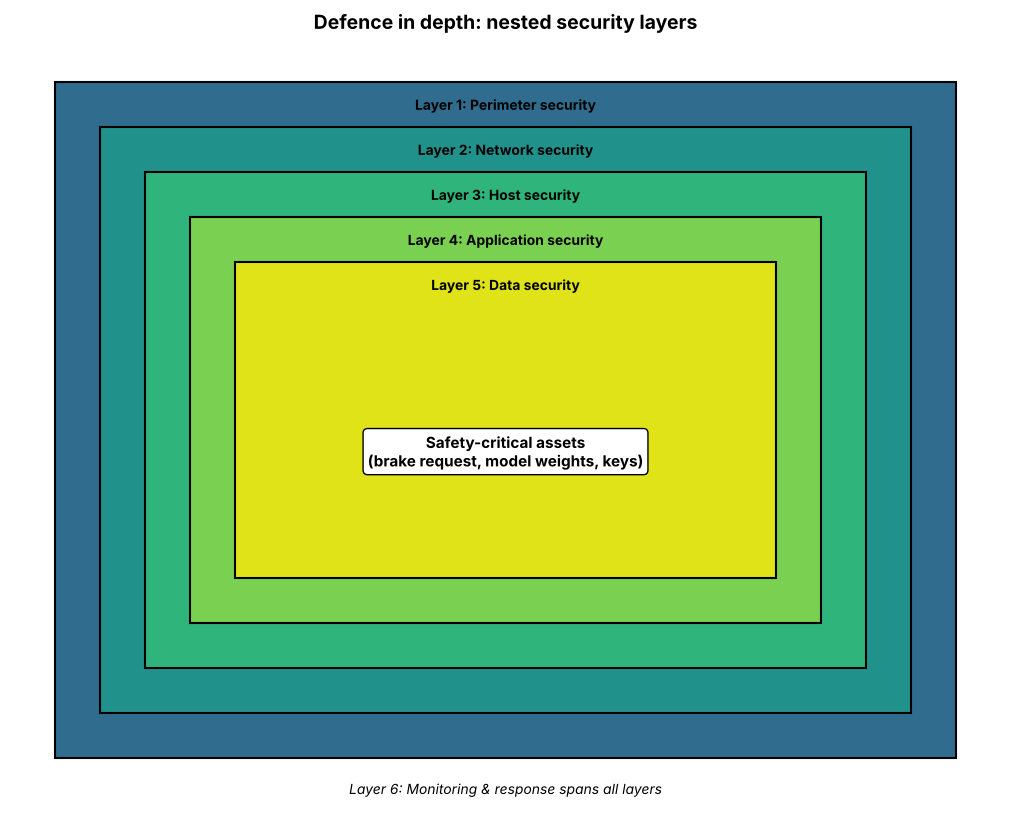

--- Figure (text summary) ---
  Outer to inner: Perimeter security > Network security > Host security > Application security > Data security; monitoring spans all layers.


In [6]:
def visualize_defense_layers():
    """Concentric (nested) rectangles for layers 1-5; layer 6 spans all layers."""
    fig, ax = plt.subplots(figsize=(11, 8.5))
    ring_layers = list(defense_layers)[:5]
    colours = plt.cm.viridis(np.linspace(0.35, 0.95, len(ring_layers)))
    for i, (layer, colour) in enumerate(zip(ring_layers, colours)):
        ax.add_patch(plt.Rectangle((0.5 * i, 0.5 * i), 10 - i, 7.5 - i, facecolor=colour, edgecolor='black', lw=1.5))
        ax.text(5, 7.25 - 0.5 * i, layer, ha='center', va='center', fontsize=10, fontweight='bold')
    ax.text(5, 3.4, 'Safety-critical assets\n(brake request, model weights, keys)', ha='center', va='center',
            fontsize=11, fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', edgecolor='black'))
    ax.text(5, -0.4, list(defense_layers)[5] + ' spans all layers', ha='center', fontsize=10, style='italic')
    ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.8, 8); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title('Defence in depth: nested security layers', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()
    print('--- Figure (text summary) ---')
    print('  Outer to inner: ' + ' > '.join(l.split(': ')[1] for l in ring_layers) + '; monitoring spans all layers.')

visualize_defense_layers()

## 5. Security controls mapping

The matrix shows which control appears at which surface. Two caveats:
- A control's *name* says little about its *effectiveness* against a specific threat. "Link integrity protection" at the sensor surface stops someone tampering with the camera cable, but it does nothing against an adversarial patch in the scene.
- Coverage is not risk. A surface with many controls may still carry a high residual risk, and the TARA (Notebook 2) decides.

In [7]:
def map_controls_to_surfaces(surfaces):
    """Map security controls (rows) to attack surfaces (columns)."""
    all_controls = sorted({c for s in surfaces for c in s.mitigations})
    return pd.DataFrame([{'Control': c, **{s.id: 'X' if c in s.mitigations else '' for s in surfaces}}
                         for c in all_controls])

control_matrix = map_controls_to_surfaces(attack_surfaces)
print('Security controls coverage matrix (columns = attack surface IDs)')
print('=' * 100)
print(control_matrix.to_string(index=False))
per_surface = (control_matrix.drop(columns='Control') == 'X').sum()
print('\nControls per surface: ' + ', '.join(f'{k}: {v}' for k, v in per_surface.items()))

Security controls coverage matrix (columns = attack surface IDs)
                                                  Control AS-001 AS-002 AS-003 AS-004 AS-005 AS-006 AS-007 AS-008
                                     A/B partition scheme                                                       X
                                      Certificate pinning             X                                          
                                   Certificate revocation                           X                            
                                Code signing verification                                                       X
                               Diagnostic session logging      X                                                 
                                       Freshness counters                                                X       
                  Gateway filtering of diagnostic traffic      X                                                 
                       

## 6. Vulnerability assessment with CVSS v3.1

CVSS v3.1 (FIRST) scores a *vulnerability*. For Scope Unchanged (S:U):

- Impact sub-score ISS = 1 − (1 − C)(1 − I)(1 − A); Impact = 6.42 × ISS
- Exploitability = 8.22 × AV × AC × PR × UI
- Base score = Roundup(min(Impact + Exploitability, 10)), or 0 if Impact ≤ 0

For Scope Changed (S:C): Impact = 7.52(ISS − 0.029) − 3.25(ISS − 0.02)^15, and Base = Roundup(min(1.08 × (Impact + Exploitability), 10)).

CVSS v3.1 has **no safety metric**. CVSS v4.0 (2023) adds a *supplemental* Safety metric, which does not change the score, so safety is reported here as a separate column.
For ISO/SAE 21434, Annex G.3 maps only the **exploitability** sub-score to attack feasibility:
2.96–3.89 High, 2.00–2.95 Medium, 1.06–1.99 Low, 0.12–1.05 Very Low.

The implementation below gives the same results as `avsafety.iso21434.cvss31_base_score`.

In [8]:
_AV = {'N': 0.85, 'A': 0.62, 'L': 0.55, 'P': 0.20}
_AC = {'L': 0.77, 'H': 0.44}
_PR_U = {'N': 0.85, 'L': 0.62, 'H': 0.27}
_PR_C = {'N': 0.85, 'L': 0.68, 'H': 0.50}
_UI = {'N': 0.85, 'R': 0.62}
_CIA = {'H': 0.56, 'L': 0.22, 'N': 0.0}

def roundup(x):
    """CVSS v3.1 Roundup (specification Appendix A)."""
    i = round(x * 100000)
    return i / 100000.0 if i % 10000 == 0 else (math.floor(i / 10000) + 1) / 10.0

def parse(vector):
    return dict(p.split(':') for p in vector.split('/') if not p.startswith('CVSS'))

def cvss31_exploitability(vector):
    m = parse(vector)
    pr = (_PR_C if m['S'] == 'C' else _PR_U)[m['PR']]
    return 8.22 * _AV[m['AV']] * _AC[m['AC']] * pr * _UI[m['UI']]

def cvss31_base_score(vector):
    m = parse(vector)
    iss = 1 - (1 - _CIA[m['C']]) * (1 - _CIA[m['I']]) * (1 - _CIA[m['A']])
    impact = 6.42 * iss if m['S'] == 'U' else 7.52 * (iss - 0.029) - 3.25 * (iss - 0.02) ** 15
    if impact <= 0:
        return 0.0
    expl = cvss31_exploitability(vector)
    return roundup(min(impact + expl, 10)) if m['S'] == 'U' else roundup(min(1.08 * (impact + expl), 10))

def severity(score):
    return 'None' if score == 0 else 'Low' if score < 4 else 'Medium' if score < 7 else 'High' if score < 9 else 'Critical'

def feasibility_from_cvss_exploitability(e):
    return 'High' if e >= 2.96 else 'Medium' if e >= 2.00 else 'Low' if e >= 1.06 else 'Very Low'

# Self-checks against the FIRST specification examples / repository unit tests
for v, s in [('AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H', 9.8), ('AV:N/AC:L/PR:N/UI:N/S:C/C:H/I:H/A:H', 10.0),
             ('AV:L/AC:L/PR:L/UI:N/S:U/C:H/I:H/A:H', 7.8), ('AV:N/AC:H/PR:N/UI:N/S:U/C:H/I:H/A:H', 8.1),
             ('AV:N/AC:L/PR:N/UI:R/S:C/C:L/I:L/A:N', 6.1)]:
    assert cvss31_base_score('CVSS:3.1/' + v) == s, v
print('CVSS v3.1 implementation passes reference checks.')

CVSS v3.1 implementation passes reference checks.


In [9]:
vulnerabilities = [
    ('CAN injection via OBD-II diagnostic port (no gateway filtering)', 'CVSS:3.1/AV:L/AC:L/PR:N/UI:N/S:U/C:L/I:H/A:H', 'Present'),
    ('Remote code execution in telematics unit', 'CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H', 'Present'),
    ('Bluetooth pairing bypass in infotainment', 'CVSS:3.1/AV:A/AC:L/PR:N/UI:N/S:U/C:L/I:L/A:N', 'Negligible'),
    ('Adversarial patch on a traffic sign (DNN misclassification)', 'CVSS:3.1/AV:P/AC:L/PR:N/UI:N/S:U/C:N/I:H/A:N', 'Present'),
]
rows = []
for name, vec, safety in vulnerabilities:
    score, expl = cvss31_base_score(vec), cvss31_exploitability(vec)
    rows.append({'Vulnerability': name, 'Vector': vec.replace('CVSS:3.1/', ''), 'Base score': score,
                 'Severity': severity(score), 'Exploitability': round(expl, 2),
                 '21434 feasibility (G.3)': feasibility_from_cvss_exploitability(expl),
                 'Safety (v4.0 supplemental, reported separately)': safety})
cvss_df = pd.DataFrame(rows)
display(cvss_df)
print('--- CVSS (text summary) ---')
for r in cvss_df.to_dict('records'):
    print(f"  {r['Vulnerability']}: {r['Base score']} ({r['Severity']}), exploitability {r['Exploitability']} "
          f"-> {r['21434 feasibility (G.3)']} feasibility; safety: {r['Safety (v4.0 supplemental, reported separately)']}")

,Vulnerability,Vector,Base score,Severity,Exploitability,21434 feasibility (G.3),"Safety (v4.0 supplemental, reported separately)"
0,CAN injection via OBD-II diagnostic port (no gateway filtering),AV:L/AC:L/PR:N/UI:N/S:U/C:L/I:H/A:H,8.0,High,2.52,Medium,Present
1,Remote code execution in telematics unit,AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,9.8,Critical,3.89,High,Present
2,Bluetooth pairing bypass in infotainment,AV:A/AC:L/PR:N/UI:N/S:U/C:L/I:L/A:N,5.4,Medium,2.84,Medium,Negligible
3,Adversarial patch on a traffic sign (DNN misclassification),AV:P/AC:L/PR:N/UI:N/S:U/C:N/I:H/A:N,4.6,Medium,0.91,Very Low,Present


--- CVSS (text summary) ---
  CAN injection via OBD-II diagnostic port (no gateway filtering): 8.0 (High), exploitability 2.52 -> Medium feasibility; safety: Present
  Remote code execution in telematics unit: 9.8 (Critical), exploitability 3.89 -> High feasibility; safety: Present
  Bluetooth pairing bypass in infotainment: 5.4 (Medium), exploitability 2.84 -> Medium feasibility; safety: Negligible
  Adversarial patch on a traffic sign (DNN misclassification): 4.6 (Medium), exploitability 0.91 -> Very Low feasibility; safety: Present


**Limits of CVSS for perception.** CVSS rates the adversarial patch as hard to exploit (AV:P gives Very Low feasibility under G.3), yet the attack tree shows it to be one of the cheapest attacks.
CVSS was designed for software vulnerabilities in IT systems. It does not capture physical-world sensor attacks or the scalability of a remote exploit across a fleet.
Use it for component vulnerabilities, e.g. in vulnerability management (cl. 8.5), and use attack potential for TARA feasibility.

## 7. Intrusion detection concepts (brief)

A simple CAN intrusion detection system (IDS) uses the fact that most CAN frames are **periodic**. It learns the period of each ID and flags (a) unknown IDs and (b) frames that arrive much earlier or later than expected, which is typical of injection.
The demo below is deliberately minimal. [Notebook 4 — CAN bus intrusion detection](04_can_bus_intrusion_detection.ipynb) covers realistic traffic, attack types and evaluation in depth.

> **Illustrative data:** CAN traffic below is synthetic.

In [10]:
class CANTimingIDS:
    """Minimal per-ID timing detector: unknown IDs and inter-arrival-time z-scores."""

    def __init__(self, threshold=4.0):
        self.threshold = threshold
        self.profiles, self.last_seen = {}, {}

    def learn_baseline(self, messages):
        by_id = {}
        for m in messages:
            by_id.setdefault(m['id'], []).append(m['timestamp'])
        for can_id, ts in by_id.items():
            d = np.diff(ts)
            self.profiles[can_id] = {'mean': d.mean(), 'std': d.std()}
            self.last_seen[can_id] = ts[-1]          # continue from the end of the training data

    def check(self, msg):
        can_id = msg['id']
        if can_id not in self.profiles:
            return 'UNKNOWN_ID'
        p = self.profiles[can_id]
        z = abs(msg['timestamp'] - self.last_seen[can_id] - p['mean']) / (p['std'] + 1e-9)
        if z > self.threshold:
            return 'TIMING_ANOMALY'                  # do not update last_seen with a suspicious frame
        self.last_seen[can_id] = msg['timestamp']
        return None

# Per-ID periodic traffic: each ID has its own clock (the original version shared one clock, which made every
# ID look 180 ms periodic and produced a 100 % false-positive rate on the test data).
can_ids, periods = [0x100, 0x200, 0x300, 0x400], [0.010, 0.020, 0.050, 0.100]
duration = 12.0
traffic = []
for can_id, period in zip(can_ids, periods):
    n = int(duration / period)
    ts = np.cumsum(period + rng.normal(0, period * 0.02, n))
    traffic += [{'id': can_id, 'timestamp': t, 'label': 'normal'} for t in ts]
traffic.sort(key=lambda m: m['timestamp'])
t_split = 10.0
train = [m for m in traffic if m['timestamp'] < t_split]
test = [m for m in traffic if m['timestamp'] >= t_split]

# Inject attacks into the test window: unknown IDs and extra frames of a known ID (0x100) between legitimate ones
attacks = [{'id': 0x555, 'timestamp': t, 'label': 'attack'} for t in np.arange(10.5, 11.0, 0.1)]
attacks += [{'id': 0x100, 'timestamp': t, 'label': 'attack'} for t in np.arange(11.0031, 11.5, 0.05)]
test = sorted(test + attacks, key=lambda m: m['timestamp'])

ids = CANTimingIDS()
ids.learn_baseline(train)
print('Learned timing profiles:')
for can_id, p in ids.profiles.items():
    print(f"  ID 0x{can_id:03X}: mean {p['mean'] * 1000:.1f} ms, std {p['std'] * 1000:.2f} ms")

alerts = [ids.check(m) for m in test]
y_true = np.array([m['label'] == 'attack' for m in test])
y_pred = np.array([a is not None for a in alerts])
tp, fp = int((y_true & y_pred).sum()), int((~y_true & y_pred).sum())
fn = int((y_true & ~y_pred).sum())
print(f'\nTest window: {len(test)} frames ({y_true.sum()} injected)')
print(f'  True positives {tp}, false positives {fp}, false negatives {fn}')
print(f'  Detection rate {tp / max(y_true.sum(), 1):.1%}, false-positive rate {fp / max((~y_true).sum(), 1):.2%}')
print('  Alert types: ' + ', '.join(f'{k}: {v}' for k, v in pd.Series([a for a in alerts if a]).value_counts().items()))

Learned timing profiles:
  ID 0x100: mean 10.0 ms, std 0.20 ms
  ID 0x200: mean 20.0 ms, std 0.42 ms
  ID 0x300: mean 49.8 ms, std 0.97 ms
  ID 0x400: mean 100.1 ms, std 1.86 ms

Test window: 376 frames (15 injected)
  True positives 15, false positives 0, false negatives 0
  Detection rate 100.0%, false-positive rate 0.00%
  Alert types: TIMING_ANOMALY: 10, UNKNOWN_ID: 5


**Limits.** A timing IDS cannot tell a forged frame from a genuine one if the attacker *replaces* the legitimate sender at the right period, e.g. after silencing the ECU with bus-off attacks. Unknown-ID checks also miss spoofed known IDs.
Detection therefore complements, and does not replace, **message authentication** (AUTOSAR SecOC: truncated MAC plus freshness value).
As Notebook 2 showed, an IDS that alerts after several frames is not a safety mechanism on its own.

## Key takeaways

### Attack surface management

1. **Enumerate all interfaces**, including the physical environment of the sensors.
2. **Prioritise with the TARA.** Remote vectors typically have higher attack feasibility and fleet-wide scalability, but risk also depends on impact.
3. **Defence in depth:** no single control is sufficient, and each control must match the threat it is credited against.
4. **Continuous monitoring:** detect, respond and feed the findings back into the TARA (cl. 8, 13).

### Automotive-specific considerations

- Safety and security are interconnected (Notebook 2, co-engineering).
- Legacy protocols (CAN) lack built-in authentication; use SecOC and segmentation.
- Use **UDS Authentication 0x29** (ISO 14229-1:2020) for diagnostics; seed/key 0x27 is legacy.
- V2X messages are signed, not encrypted, and a valid signature does not mean the content is true.
- Long vehicle lifecycles require secure OTA (UN R156, ISO 24089).
- Sensor attacks in the physical environment are specific to automated vehicles. They are cheap and cannot be prevented by cryptography.

### ISO/SAE 21434 integration

| Activity | Deliverable | Clause |
|---|---|---|
| Asset identification | Asset list with properties, damage scenarios | 15.3 |
| Attack surface analysis | Interface list with attack vector classes | input to 15.4 / 15.6 |
| Threat modelling | Threat scenarios (STRIDE as heuristic) | 15.4 |
| Attack path analysis | Attack trees with AND/OR aggregation | 15.6 |
| Feasibility rating | Attack potential, CVSS exploitability or attack vector | 15.7, Annex G |
| Vulnerability analysis | CVSS base scores, triage | 8.5 |
| Control implementation | Defence-in-depth architecture, verified controls | 9.5, 10 |

## Self-assessment

1. Why is OBD-II access classified as Local or Physical rather than Adjacent?
2. An OR node has children with attack potential 7, 14 and 25. What is its attack potential? What changes for an AND node?
3. Compute the CVSS v3.1 base score of AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H and its Annex G.3 feasibility.
4. Why does signing camera frames not protect against an adversarial patch?
5. Why are V2X broadcast messages signed but not encrypted, and what does a valid signature *not* guarantee?
6. What is the difference between UDS services 0x27 and 0x29?

<details>
<summary>Answers</summary>

1. The attacker needs a tester connected to the vehicle, not radio proximity. Adjacent means reachable via a shared radio or logical network segment.
2. OR: 7, the most feasible child. AND: aggregate factor-wise (here, the maximum of each factor over the children). The result is at least as hard as the hardest child.
3. Exploitability 8.22 × 0.85 × 0.77 × 0.85 × 0.85 ≈ 3.89; impact 6.42 × 0.915 ≈ 5.87; base = Roundup(9.76) = **9.8 (Critical)**. Exploitability ≥ 2.96 gives **High** feasibility.
4. The patch changes the scene. The camera records and transmits authentic pixels of a manipulated world, so signatures only detect changes *after* capture.
5. The messages are meant for every receiver in range, so confidentiality is not needed. Privacy comes from pseudonym certificates. A valid signature proves that the sender holds a valid certificate, not that the content is true.
6. 0x27 SecurityAccess uses a seed/key challenge with a shared (often weak or leaked) algorithm. 0x29 Authentication, added in ISO 14229-1:2020, uses certificate/PKI-based authentication with roles.
</details>

## References

1. ISO/SAE 21434:2021, *Road vehicles — Cybersecurity engineering* (cl. 8.5, 15.6, 15.7; Annex G).
2. UNECE, UN Regulation No. 155 (CSMS, 2021) and No. 156 (SUMS, 2021). https://unece.org/transport/documents/2021/03/standards/un-regulation-no-155-cyber-security-and-cyber-security
3. FIRST (2019). *CVSS v3.1 Specification Document*. https://www.first.org/cvss/v3.1/specification-document ; FIRST (2023). *CVSS v4.0 Specification Document*. https://www.first.org/cvss/v4.0/specification-document
4. ISO 14229-1:2020, *Road vehicles — Unified diagnostic services (UDS) — Part 1: Application layer*.
5. IEEE 1609.2-2022, *Standard for Wireless Access in Vehicular Environments — Security Services*; ETSI TS 103 097 (security header and certificate formats); ETSI TS 102 940/941 (ITS security architecture, trust and privacy management).
6. AUTOSAR, *Specification of Secure Onboard Communication* (SWS SecOC). https://www.autosar.org
7. Schneier, B. (1999). Attack Trees. *Dr. Dobb's Journal*, 24(12). https://www.schneier.com/academic/archives/1999/12/attack_trees.html
8. Miller, C., Valasek, C. (2015). *Remote Exploitation of an Unaltered Passenger Vehicle*. Black Hat USA.
9. NHTSA (2022). *Cybersecurity Best Practices for the Safety of Modern Vehicles*. https://www.nhtsa.gov/document/cybersecurity-best-practices-safety-modern-vehicles-2022
10. SAE J3061 (2016). *Cybersecurity Guidebook for Cyber-Physical Vehicle Systems* (predecessor, superseded in practice by ISO/SAE 21434).

## Further practice

- Companion workshop exercise: [TARA exercise](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/10_tara_exercise.ipynb) (AI Perception Safety Workshop).
- Extend the attack tree with a GNSS-spoofing branch (AS-006) and re-run the aggregation.

---
**Navigation:** ← [TARA](02_tara.ipynb) · [Module index](README.md) · [CAN bus intrusion detection](04_can_bus_intrusion_detection.ipynb) →